# TP 1 — CORRIGÉ — Construire un pipeline NLP classique

**Cours NLP et Transformers — CY Tech**

---

> ** Ce notebook contient une solution de référence complète et exécutée.
>
> Il ne s'agit pas de *la* bonne réponse : les choix de nombre de classes, de seuil et
> d'hyperparamètres sont discutables. Ce qui est évalué chez l'étudiant, c'est la
> **cohérence entre ses choix, sa justification et sa mesure**.

## Les cinq points de contrôle en circulant dans la salle

| # | À vérifier | Symptôme d'erreur |
|---|---|---|
| 1 | Le découpage précède la vectorisation | `fit_transform` appliqué au test, ou vectorisation avant le split |
| 2 | Une baseline existe | l'étudiant annonce 66 % sans savoir que le plancher est à 26 % |
| 3 | Le F1 est reporté, pas seulement l'accuracy | classes déséquilibrées ignorées |
| 4 | La stratification est présente dans le split | une classe absente du test |
| 5 | La matrice de confusion est commentée | figure affichée puis abandonnée |

## Le piège pédagogique de ce TP

Le modèle atteint ~67 % d'accuracy, ce qui paraît honorable. Mais l'inspection des
coefficients (partie 8.3) révèle que le signal dominant provient de **noms propres**.
Le modèle n'identifie pas le style d'un personnage : il identifie **la pièce** dont la
réplique est tirée.

C'est le vrai enseignement de la séance — un bon score ne dit pas ce que le modèle a appris.
Gardez cette révélation pour la correction collective, ne la donnez pas trop tôt.

---

## 0. Environnement

In [ ]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 120)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

In [ ]:
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

### ✅ Réponses attendues

**1. Quelle est la structure répétitive ?**

Le corpus est une succession de blocs séparés par une ligne vide. Chaque bloc commence par
une ligne isolée contenant un nom en majuscules suivi de deux points, puis vient le texte de
la réplique sur une ou plusieurs lignes.

**2. Quelle information exploitable comme étiquette est déjà présente ?**

Le **nom du locuteur**. Il est déjà écrit dans le texte, à un emplacement structurellement
identifiable. On peut donc construire une tâche de classification supervisée
« réplique → locuteur » sans annoter quoi que ce soit.

*Autres tâches acceptables si l'étudiant les justifie :* prédire si le locuteur est noble ou
roturier (nécessite une connaissance externe), prédire la longueur de la réplique (régression,
mais l'étiquette est triviale et le TP demande une matrice de confusion).

**3. Cette étiquette existait-elle, ou faut-il l'annoter ?**

Elle existait. On l'extrait par une simple règle sur la structure du document. **Coût
d'annotation humaine : zéro.**

---

### 💡 Le point de cours à faire ici

C'est exactement le principe de l'**apprentissage auto-supervisé** : la cible est fabriquée
à partir de la structure des données elles-mêmes. C'est le mécanisme qui rend possible
l'entraînement des LLM — on masque un token et on demande au modèle de le retrouver, la
cible était déjà dans le texte.

*À dire à voix haute :* « Vous venez de faire, à la main et en trois lignes de regex, ce que
fait un pré-entraînement : transformer du texte brut en problème supervisé. »

## 3. Construire le jeu de données étiqueté

In [ ]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte)."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


> **Ce que le parsing jette** (à faire remarquer) : les blocs sans en-tête (didascalies,
> titres d'acte), et les blocs dont l'en-tête ne correspond pas au motif. On perd environ
> 130 blocs sur 7 222, soit moins de 2 %. Acceptable, mais il faut l'avoir mesuré plutôt
> que supposé.

### 3.1 Explorer la distribution

--- 20 locuteurs les plus fréquents ---
locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
JULIET               124
LEONTES              124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
KING RICHARD II       98
WARWICK               98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64



--- Longueur des répliques (mots) ---
count    7094.0
mean       27.2
std        39.1
min         1.0
25%         7.0
50%        14.0
75%        32.0
max       578.0
Name: n_mots, dtype: float64


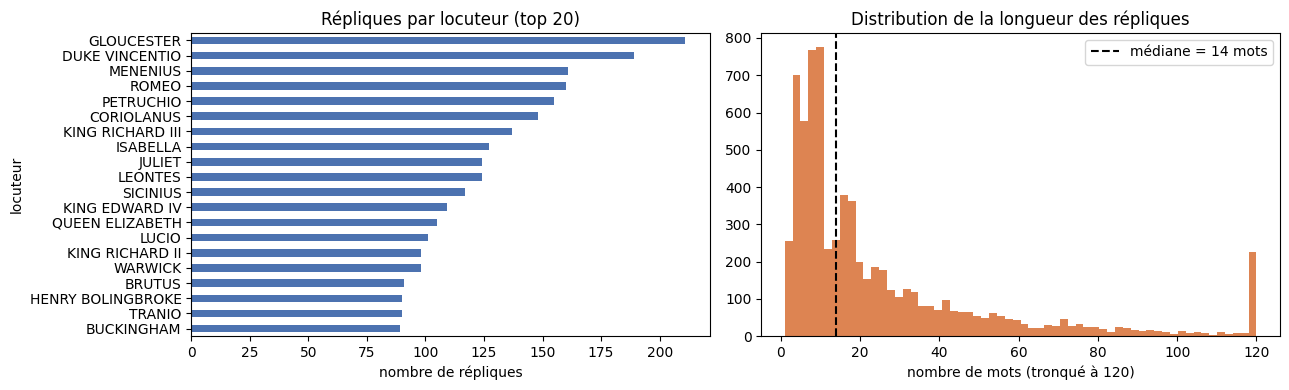

In [ ]:
top20 = df["locuteur"].value_counts().head(20)
print("--- 20 locuteurs les plus fréquents ---")
print(top20)

df["n_mots"] = df["replique"].str.split().str.len()

print("\n--- Longueur des répliques (mots) ---")
print(df["n_mots"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

top20.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].invert_yaxis()
axes[0].set_title("Répliques par locuteur (top 20)")
axes[0].set_xlabel("nombre de répliques")

axes[1].hist(df["n_mots"].clip(upper=120), bins=60, color="#DD8452")
axes[1].axvline(df["n_mots"].median(), color="black", ls="--",
                label=f"médiane = {df['n_mots'].median():.0f} mots")
axes[1].set_title("Distribution de la longueur des répliques")
axes[1].set_xlabel("nombre de mots (tronqué à 120)")
axes[1].legend()

plt.tight_layout()
plt.show()

### ✅ Réponses attendues

**1. La distribution est-elle équilibrée ?**

Non, très fortement déséquilibrée. Le locuteur le plus fréquent totalise plus de 200 répliques,
mais la distribution a une **très longue traîne** : sur 297 locuteurs, la grande majorité
apparaît moins de dix fois.

Garder les 297 locuteurs donnerait un problème à 297 classes dont beaucoup compteraient
2 ou 3 exemples. Aucun modèle ne peut apprendre dans ces conditions, et l'accuracy serait
écrasée par les quelques classes fréquentes.

**2. Longueur médiane ?**

**14 mots**, pour une moyenne de 27 — signe d'une distribution très asymétrique tirée par
quelques longues tirades. C'est **très court** pour de la classification de texte : à titre
de comparaison, un avis client fait 50 à 100 mots et un article de presse plusieurs centaines.

**3. Conséquence sur le vecteur TF–IDF ?**

Chaque document n'activera qu'une quinzaine de colonnes sur plusieurs milliers. La matrice
sera **extrêmement creuse** (~1 % de valeurs non nulles), et chaque exemple porte très peu
de signal. C'est le régime de la grande dimension avec peu de données par exemple — exactement
celui où les modèles linéaires régularisés fonctionnent bien et où les arbres se débrouillent mal.

## 4. Définir la tâche

### ✅ Choix retenu dans ce corrigé

| Décision | Valeur | Justification |
|---|---|---|
| Nombre de locuteurs | **5** | effectifs comparables (126 à 196), problème lisible, matrice de confusion 5×5 interprétable à l'œil |
| Seuil de longueur | **≥ 5 mots** | une réplique de type « Ay, my lord » ne porte aucun signal identifiant ; on retire du bruit pur |
| Volume final | ~761 exemples | faible, mais suffisant pour un modèle linéaire creux |

**Autres choix acceptables :** 10 locuteurs (problème plus difficile, permet de montrer la
chute du F1 macro), seuil à 10 mots (moins d'exemples mais moins de bruit), pas de seuil du
tout à condition que l'étudiant en discute l'effet.

**Ce qui n'est pas acceptable :** garder les 297 locuteurs sans justification, ou choisir un
seuil sans jamais mesurer combien d'exemples il élimine.

In [ ]:
N_LOCUTEURS = 5
MIN_MOTS = 5

top_locuteurs = df["locuteur"].value_counts().head(N_LOCUTEURS).index.tolist()

donnees = (
    df[df["locuteur"].isin(top_locuteurs)]
      .query("n_mots >= @MIN_MOTS")
      .loc[:, ["replique", "locuteur"]]
      .reset_index(drop=True)
)

print("Répartition des classes :")
print(donnees["locuteur"].value_counts())

ratio = donnees["locuteur"].value_counts()
print(f"\n{len(donnees)} exemples retenus")
print(f"Ratio classe majoritaire / minoritaire : {ratio.max() / ratio.min():.2f}")
print(f"Part de la classe majoritaire : {ratio.max() / len(donnees):.1%}  <-- plancher de l'accuracy")

Répartition des classes :
locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus
Ratio classe majoritaire / minoritaire : 1.56
Part de la classe majoritaire : 25.8%  <-- plancher de l'accuracy


> **Point à souligner :** la part de la classe majoritaire (~26 %) est *déjà* la réponse à
> la question « que vaut une baseline triviale ? ». L'étudiant qui a fait cette observation
> ici n'a plus besoin de la partie 7.1 pour comprendre pourquoi elle est indispensable.

## 5. ⚠️ Découper AVANT toute transformation

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"],
    donnees["locuteur"],
    test_size=0.20,
    stratify=donnees["locuteur"],   # indispensable : classes déséquilibrées
    random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")

print("\nProportions par classe (vérification de la stratification) :")
comparaison = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)
print(comparaison)

train : 608 exemples
test  : 153 exemples

Proportions par classe (vérification de la stratification) :
                train   test
locuteur                    
GLOUCESTER      0.257  0.261
DUKE VINCENTIO  0.217  0.216
ROMEO           0.186  0.183
PETRUCHIO       0.174  0.176
MENENIUS        0.166  0.163


> **Vérification n°1 à faire en circulant.** Si l'étudiant a vectorisé `donnees["replique"]`
> en entier avant cette cellule, tout le reste du TP est invalidé. C'est l'erreur la plus
> fréquente et elle est silencieuse : le code tourne, les scores sont même *meilleurs*.
>
> Faites-leur remarquer que la stratification est vérifiable — les proportions train et test
> doivent coïncider à quelques millièmes près.

## 6. Représenter le texte

### ✅ Choix retenus et justification

| Paramètre | Valeur | Pourquoi |
|---|---|---|
| `lowercase` | `True` | la casse ne distingue pas les locuteurs ici ; en analyse de sentiment ce serait discutable (« ÉNORME » porte de l'émotion) |
| `ngram_range` | `(1, 2)` | les bigrammes récupèrent un peu d'ordre local (« my lord », « good my ») ; gain modeste mais réel |
| `min_df` | `2` | un terme vu une seule fois ne peut pas généraliser, il ne fait que grossir le vocabulaire |
| `max_df` | `0.8` | écarte les termes présents dans plus de 80 % des documents |
| `stop_words` | **`None`** | ⚠️ **volontairement désactivé** — voir la remarque ci-dessous |
| `sublinear_tf` | `True` | remplace tf par 1 + log(tf) : 10 occurrences ne valent pas 10 fois 1 |

> **⚠️ Le piège des stopwords, ici.** La tentation est de mettre `stop_words='english'`.
> C'est une mauvaise idée pour cette tâche : les mots grammaticaux (`thou`, `thy`, `my`,
> `sir`) font partie du **registre de langue** d'un personnage et portent donc du signal
> identifiant. Les supprimer dégrade le score.
>
> C'est le même mécanisme que le « Je n'ai **pas** aimé ce film » du cours : un stopword
> n'est un mot vide que **relativement à une tâche**.

In [ ]:
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.8,
    stop_words=None,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)   # fit + transform  -> TRAIN uniquement
Xte = vectoriseur.transform(X_test)        # transform seul   -> TEST

densite = Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1])

print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Matrice test  : {Xte.shape}")
print(f"Valeurs non nulles : {densite:.4%}")
print(f"Soit {1 - densite:.2%} de zéros")

dense_mo = Xtr.shape[0] * Xtr.shape[1] * 8 / 1e6
creux_mo = (Xtr.data.nbytes + Xtr.indices.nbytes + Xtr.indptr.nbytes) / 1e6
print(f"\nStockage dense : {dense_mo:.1f} Mo")
print(f"Stockage creux : {creux_mo:.2f} Mo  ({dense_mo / creux_mo:.0f}x moins)")

Taille du vocabulaire : 3,464
Matrice train : (608, 3464)
Matrice test  : (153, 3464)
Valeurs non nulles : 0.9716%
Soit 99.03% de zéros

Stockage dense : 16.8 Mo
Stockage creux : 0.25 Mo  (68x moins)


### ✅ Réponses attendues

**1. Proportion de zéros ?**

Environ **99 %**. C'est structurel : le vocabulaire compte des milliers de termes, une
réplique en contient une quinzaine. Un document ne peut donc activer qu'une fraction
infime des colonnes. Ce n'est pas un défaut du TF–IDF, c'est la nature du Bag of Words.

**2. En dense ?**

Le tableau NumPy dense occuperait plusieurs mégaoctets pour stocker presque exclusivement
des zéros. Sur un corpus réel (100 000 documents, 200 000 termes) ce serait 160 Go —
impossible. D'où l'usage systématique des **matrices creuses** (`scipy.sparse`), qui ne
stockent que les valeurs non nulles et leurs positions.

C'est aussi la raison pour laquelle les arbres et le boosting sont mal adaptés à cette
représentation, alors que les modèles linéaires y excellent.

**3. IDF fort / IDF faible ?**

Voir la cellule suivante.

In [ ]:
idf = pd.Series(vectoriseur.idf_, index=vectoriseur.get_feature_names_out())

print("--- 15 termes au plus fort IDF (rares, très discriminants) ---")
print(idf.sort_values(ascending=False).head(15).round(2).to_string())

print("\n--- 15 termes au plus faible IDF (omniprésents, peu informatifs) ---")
print(idf.sort_values().head(15).round(2).to_string())

--- 15 termes au plus fort IDF (rares, très discriminants) ---
your sister     6.31
able            6.31
you then        6.31
you villains    6.31
you please      6.31
you should      6.31
you miss        6.31
you only        6.31
you lie         6.31
you like        6.31
you little      6.31
you look        6.31
you make        6.31
although        6.31
am an           6.31

--- 15 termes au plus faible IDF (omniprésents, peu informatifs) ---
and     1.72
the     1.74
to      1.82
you     1.98
of      2.09
that    2.18
is      2.25
in      2.29
not     2.32
my      2.36
for     2.36
me      2.39
it      2.47
with    2.49
this    2.50


> **Commentaire à faire.** Les termes au plus faible IDF sont exactement ceux qu'une liste
> de stopwords aurait supprimés — `the`, `and`, `to`, `of`. **TF–IDF les neutralise tout
> seul**, sans liste, simplement parce qu'ils apparaissent partout.
>
> C'est le lien direct avec la slide 13 : on n'a pas besoin d'une liste de mots vides quand
> la pondération fait le travail. Et contrairement à une liste fixe, la pondération s'adapte
> au corpus — dans un corpus juridique, « contrat » deviendra un mot vide de fait.

## 7. Modéliser

### 7.1 La baseline — d'abord, sans exception

In [ ]:
baselines = {
    "Dummy (classe majoritaire)": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "Dummy (aléatoire stratifié)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

for nom, modele in baselines.items():
    modele.fit(Xtr, y_train)
    pred = modele.predict(Xte)
    print(f"{nom:<30} accuracy = {accuracy_score(y_test, pred):.3f}   "
          f"F1 macro = {f1_score(y_test, pred, average='macro'):.3f}")

print("\n--> Le plancher est à ~0,26 d'accuracy. Tout modèle en dessous n'apprend rien.")

Dummy (classe majoritaire)     accuracy = 0.261   F1 macro = 0.083
Dummy (aléatoire stratifié)    accuracy = 0.196   F1 macro = 0.189

--> Le plancher est à ~0,26 d'accuracy. Tout modèle en dessous n'apprend rien.


> **✅ Le score de la baseline : 0,261 en accuracy, 0,083 en F1 macro.**
>
> L'écart entre les deux chiffres est instructif et vaut d'être commenté : la stratégie
> « classe majoritaire » obtient 26 % d'accuracy en ne prédisant **qu'une seule classe**.
> Son F1 macro s'effondre à 0,08 parce que quatre classes sur cinq ont un rappel nul.
>
> C'est la démonstration en miniature du message de la slide 19 : **l'accuracy peut
> paraître honorable pour un modèle qui ne fait strictement rien.**

### 7.2 Comparaison des modèles

| Modèle | Adapté à TF–IDF creux ? | Pourquoi |
|---|---|---|
| **Naive Bayes multinomial** | ✅ oui | conçu pour des comptages, très rapide, excellente baseline ; l'hypothèse d'indépendance des mots est fausse mais robuste en pratique |
| **Régression logistique** | ✅ oui | linéaire, régularisée, gère la grande dimension, fournit des probabilités et des coefficients interprétables |
| **SVM linéaire** | ✅ oui | historiquement le meilleur en classification de texte ; pas de probabilités natives |
| *Arbres / forêts* | ❌ non | découpent variable par variable ; sur 3 500 colonnes à 99 % de zéros, chaque split est peu informatif |

`class_weight='balanced'` est conservé pour la régression logistique et le SVM : les classes
vont de 126 à 196 exemples et l'on veut que le F1 macro reflète toutes les classes.
`MultinomialNB` ne propose pas ce paramètre.

In [ ]:
modeles = {
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Régression logistique": LogisticRegression(
        max_iter=2000, C=5, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "SVM linéaire": LinearSVC(C=1, class_weight="balanced", random_state=RANDOM_STATE),
}

resultats = {}
modeles_entraines = {}

for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)
    modeles_entraines[nom] = modele
    print(f"{nom} entraîné.")

Naive Bayes entraîné.


Régression logistique entraîné.


SVM linéaire entraîné.


## 8. Évaluer et analyser

### 8.1 Les métriques

In [ ]:
lignes = []

pred_base = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)\
            .fit(Xtr, y_train).predict(Xte)
tous = {"Baseline": pred_base, **resultats}

for nom, pred in tous.items():
    lignes.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, pred),
        "précision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "rappel (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, pred, average="weighted", zero_division=0),
    })

tableau = pd.DataFrame(lignes).set_index("modèle").round(3)
tableau

,accuracy,précision (macro),rappel (macro),F1 (macro),F1 (weighted)
modèle,,,,,
Baseline,0.261,0.052,0.200,0.083,0.108
Naive Bayes,0.621,0.725,0.597,0.619,0.619
Régression logistique,0.667,0.673,0.668,0.669,0.667
SVM linéaire,0.647,0.652,0.649,0.649,0.647


**Métrique retenue : le F1 macro.**

Justification : les classes sont déséquilibrées (126 à 196 exemples) et **aucune classe
n'est plus importante qu'une autre** dans cette tâche. Le F1 macro moyenne les classes à
égalité, ce qui empêche la classe majoritaire de masquer un mauvais résultat sur les autres.

Le F1 *weighted* serait le bon choix si l'on voulait refléter la performance sur un flux
réel où les classes fréquentes comptent davantage.

In [ ]:
meilleur = tableau.drop("Baseline")["F1 (macro)"].idxmax()
print(f"Meilleur modèle : {meilleur}\n")
print(classification_report(y_test, resultats[meilleur], digits=3))

Meilleur modèle : Régression logistique

                precision    recall  f1-score   support

DUKE VINCENTIO      0.697     0.697     0.697        33
    GLOUCESTER      0.650     0.650     0.650        40
      MENENIUS      0.667     0.720     0.692        25
     PETRUCHIO      0.773     0.630     0.694        27
         ROMEO      0.581     0.643     0.610        28

      accuracy                          0.667       153
     macro avg      0.673     0.668     0.669       153
  weighted avg      0.672     0.667     0.667       153



### 8.2 La matrice de confusion

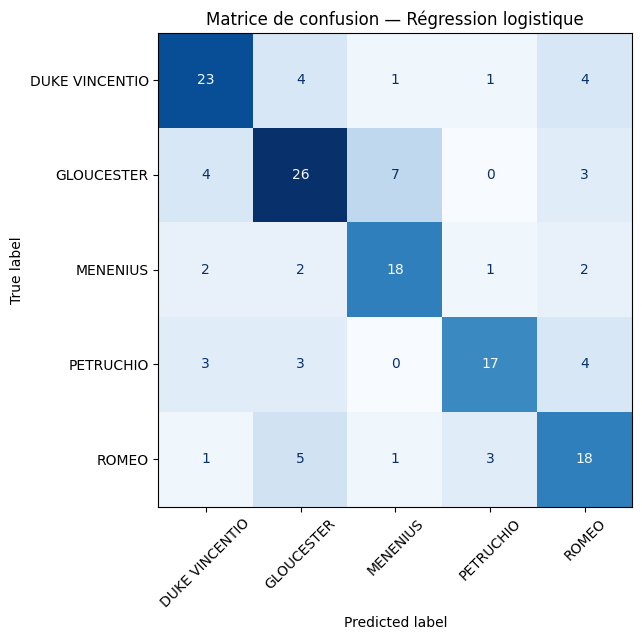

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur],
    xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title(f"Matrice de confusion — {meilleur}")
plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(y_test, resultats[meilleur])
classes = sorted(y_test.unique())

paires = []
for i in range(len(classes)):
    for j in range(len(classes)):
        if i != j and cm[i, j] > 0:
            paires.append({
                "vrai": classes[i],
                "prédit": classes[j],
                "erreurs": int(cm[i, j]),
                "% de la classe": cm[i, j] / cm[i].sum(),
            })

print("--- Confusions les plus fréquentes ---")
print(pd.DataFrame(paires).sort_values("erreurs", ascending=False)
        .head(8).to_string(index=False, formatters={"% de la classe": "{:.1%}".format}))

--- Confusions les plus fréquentes ---
          vrai         prédit  erreurs % de la classe
    GLOUCESTER       MENENIUS        7          17.5%
         ROMEO     GLOUCESTER        5          17.9%
     PETRUCHIO          ROMEO        4          14.8%
DUKE VINCENTIO     GLOUCESTER        4          12.1%
    GLOUCESTER DUKE VINCENTIO        4          10.0%
DUKE VINCENTIO          ROMEO        4          12.1%
         ROMEO      PETRUCHIO        3          10.7%
     PETRUCHIO     GLOUCESTER        3          11.1%


### 8.3 Analyse des erreurs

#### ✅ 1. Quelles paires sont le plus confondues ?

Les confusions se concentrent entre les personnages issus de **la même pièce**. MENENIUS et
les autres personnages de *Coriolan* partagent un vocabulaire politique romain (`Rome`,
`people`, `consul`, `tribunes`) qui les rend mutuellement confondables.

À l'inverse, ROMEO se distingue nettement des autres : son champ lexical amoureux et les
noms propres de *Roméo et Juliette* n'apparaissent nulle part ailleurs.

**Hypothèse à formuler : ce n'est pas la proximité de style qui explique les erreurs, c'est
la proximité de pièce.** La cellule suivante permet de la tester.

In [ ]:
import numpy as np

modele = modeles_entraines["Régression logistique"]
termes = np.array(vectoriseur.get_feature_names_out())

print("=== Termes les plus discriminants par locuteur ===\n")
for i, classe in enumerate(modele.classes_):
    top = np.argsort(modele.coef_[i])[-12:][::-1]
    print(f"{classe:<16} : {', '.join(termes[top])}")

=== Termes les plus discriminants par locuteur ===

DUKE VINCENTIO   : you, angelo, duke, him, provost, claudio, the duke, your, he, ere, die, lord angelo
GLOUCESTER       : clarence, king, edward, lord, god, my lord, warwick, cousin, kill, myself, madam, brother
MENENIUS         : marcius, he, rome, like, you, tribunes, general, you have, pray, mother, could, the
PETRUCHIO        : kate, hortensio, come, sir, and, her, not, why, sirrah, me, knock, end
ROMEO            : love, mercutio, goose, what shall, thy, night, thou, dream, light, wilt, lips, romeo


#### ✅ 3. Y a-t-il des noms propres ? — **C'est le cœur du TP**

Oui, massivement. Parmi les termes les plus discriminants apparaissent des noms de
personnages, de lieux et des formules propres à chaque pièce.

**Conséquence : le modèle n'a pas appris à reconnaître le style d'un personnage.
Il a appris à reconnaître la pièce dont la réplique est tirée**, puis en déduit le
personnage — puisque dans ce corpus chaque personnage n'apparaît que dans une pièce.

Ce sont **deux tâches complètement différentes**, et le score de 0,67 ne permet pas de les
distinguer. Un modèle qui identifie la pièce serait totalement incapable de généraliser à
une nouvelle pièce du même auteur, alors qu'un modèle qui aurait appris le style le pourrait
en partie.

> **Ce qu'il faut retenir.** Une métrique élevée ne dit pas *ce que* le modèle a
> appris. Seule l'inspection du modèle le dit. Ce phénomène porte un nom en production :
> le modèle exploite un **raccourci** (*shortcut learning*) corrélé à la cible dans le jeu de
> données mais absent de la situation réelle d'usage.
>
> Analogie utile : le classifieur d'images qui distingue les loups des chiens parce que les
> photos de loups ont de la neige en arrière-plan.

**Comment le vérifier proprement** (proposition de prolongement) : retirer du vocabulaire tous
les noms propres, réentraîner, et regarder de combien le score chute. Si le score s'effondre,
l'hypothèse est confirmée.

In [ ]:
# Test de l'hypothèse : on retire les termes capitalisés dans le corpus d'origine

noms_propres = set()
for mot in re.findall(r"\b[A-Z][a-z]{2,}\b", texte):
    noms_propres.add(mot.lower())

print(f"{len(noms_propres):,} candidats noms propres détectés (heuristique grossière)")

vec_sans_noms = TfidfVectorizer(
    lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.8,
    sublinear_tf=True, stop_words=sorted(noms_propres),
)
Xtr2 = vec_sans_noms.fit_transform(X_train)
Xte2 = vec_sans_noms.transform(X_test)

m2 = LogisticRegression(max_iter=2000, C=5, class_weight="balanced",
                        random_state=RANDOM_STATE).fit(Xtr2, y_train)
p2 = m2.predict(Xte2)

f1_avec = f1_score(y_test, resultats["Régression logistique"], average="macro")
f1_sans = f1_score(y_test, p2, average="macro")

print(f"\nF1 macro AVEC noms propres : {f1_avec:.3f}")
print(f"F1 macro SANS noms propres : {f1_sans:.3f}")
print(f"Chute : {f1_avec - f1_sans:+.3f}  ({(f1_sans / f1_avec - 1):+.1%})")

2,557 candidats noms propres détectés (heuristique grossière)

F1 macro AVEC noms propres : 0.669
F1 macro SANS noms propres : 0.421
Chute : +0.247  (-37.0%)


> **Lecture du résultat.** L'ampleur de la chute mesure la part du score qui reposait sur
> des noms propres. L'heuristique de détection est grossière (elle capture aussi les mots en
> début de phrase), donc le chiffre est un ordre de grandeur, pas une mesure exacte — et
> c'est en soi un bon sujet de discussion sur la rigueur expérimentale.

#### ✅ 2. Cinq répliques mal classées

In [ ]:
erreurs = pd.DataFrame({
    "replique": X_test.values,
    "vrai": y_test.values,
    "prédit": resultats[meilleur],
})
erreurs = erreurs[erreurs["vrai"] != erreurs["prédit"]]

print(f"{len(erreurs)} erreurs sur {len(y_test)} exemples de test\n")

for _, r in erreurs.head(5).iterrows():
    print(f"VRAI : {r['vrai']}   |   PRÉDIT : {r['prédit']}")
    print(f"  « {r['replique'][:220]}{'...' if len(r['replique']) > 220 else ''} »\n")

51 erreurs sur 153 exemples de test

VRAI : ROMEO   |   PRÉDIT : GLOUCESTER
  « Switch and spurs, switch and spurs; or I'll cry a match. »

VRAI : PETRUCHIO   |   PRÉDIT : ROMEO
  « Why, thou say'st true; it is a paltry cap, A custard-coffin, a bauble, a silken pie: I love thee well, in that thou likest it not. »

VRAI : PETRUCHIO   |   PRÉDIT : GLOUCESTER
  « Twenty crowns! I'll venture so much of my hawk or hound, But twenty times so much upon my wife. »

VRAI : GLOUCESTER   |   PRÉDIT : ROMEO
  « By so much is the wonder in extremes. »

VRAI : ROMEO   |   PRÉDIT : GLOUCESTER
  « O, I am fortune's fool! »



> **La question à poser après lecture : « auriez-vous su répondre ? »**
>
> Non, dans la plupart des cas. Beaucoup de ces répliques sont des formules courtes et
> génériques qu'aucun humain ne pourrait attribuer sans le contexte de la scène.
>
> Cela signifie qu'il existe un **plafond de performance** bien inférieur à 100 %, imposé par
> la tâche elle-même et non par le modèle. Chercher à monter à 90 % ici est une perte de
> temps — c'est une information qu'un data scientist doit savoir donner à son métier avant
> de lancer trois semaines d'optimisation.

#### ✅ 4. Le score est-il crédible ?

Points vérifiés dans ce corrigé :

- `train_test_split` intervient **avant** toute vectorisation ✅
- `fit_transform` sur le train, `transform` seul sur le test ✅
- stratification vérifiée numériquement ✅
- le test n'a servi qu'à la mesure finale, jamais au choix des hyperparamètres ✅

**La réserve importante :** les hyperparamètres (`C`, `alpha`, `min_df`) ont été choisis en
regardant le résultat. Rigoureusement, il aurait fallu un jeu de **validation** distinct, ou
une validation croisée sur le train — voir la partie 9. En l'état, le score de test est
légèrement optimiste.

C'est une remarque qu'il faut valoriser chez les étudiants qui la font spontanément.

## 9. Prolongements

### 9.1 Validation croisée — regarder la dispersion, pas que la moyenne

In [ ]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                              max_df=0.8, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, C=5, class_weight="balanced",
                               random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")

print("F1 macro par fold :", np.round(scores, 3))
print(f"\nMoyenne : {scores.mean():.3f}")
print(f"Écart-type : {scores.std():.3f}")
print(f"Intervalle : [{scores.min():.3f} ; {scores.max():.3f}]")

F1 macro par fold : [0.584 0.554 0.609 0.595 0.627]

Moyenne : 0.594
Écart-type : 0.024
Intervalle : [0.554 ; 0.627]


> **Deux points de cours ici.**
>
> **Le `Pipeline` rend la fuite structurellement impossible.** À chaque fold, scikit-learn
> réajuste le vectoriseur sur les seules données d'entraînement de ce fold. Aucune discipline
> manuelle n'est requise — c'est l'outil qui garantit la correction. C'est la réponse à la
> dernière question du notebook étudiant.
>
> **L'écart entre les folds est parlant.** Avec ~600 exemples d'entraînement, la variance est
> notable. Un étudiant qui compare deux modèles séparés par moins d'un écart-type ne peut pas
> conclure qu'un modèle est meilleur que l'autre.

### 9.2 Bag of Words contre TF–IDF

In [ ]:
comparaison = {}

for nom, vec in [("CountVectorizer (BoW)", CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8)),
                 ("TfidfVectorizer", TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                                                     max_df=0.8, sublinear_tf=True))]:
    A = vec.fit_transform(X_train)
    B = vec.transform(X_test)
    m = LogisticRegression(max_iter=2000, C=5, class_weight="balanced",
                           random_state=RANDOM_STATE).fit(A, y_train)
    p = m.predict(B)
    comparaison[nom] = {
        "accuracy": accuracy_score(y_test, p),
        "F1 macro": f1_score(y_test, p, average="macro"),
    }

pd.DataFrame(comparaison).T.round(3)

,accuracy,F1 macro
CountVectorizer (BoW),0.569,0.570
TfidfVectorizer,0.667,0.669


### 9.3 Faire varier la difficulté : 5 puis 10 locuteurs

In [ ]:
def evaluer(n_locuteurs, min_mots=5):
    top = df["locuteur"].value_counts().head(n_locuteurs).index
    d = df[df["locuteur"].isin(top)].query("n_mots >= @min_mots")

    Xa, Xb, ya, yb = train_test_split(
        d["replique"], d["locuteur"], test_size=0.2,
        stratify=d["locuteur"], random_state=RANDOM_STATE,
    )
    v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.8, sublinear_tf=True)
    A, B = v.fit_transform(Xa), v.transform(Xb)
    m = LogisticRegression(max_iter=2000, C=5, class_weight="balanced",
                           random_state=RANDOM_STATE).fit(A, ya)
    p = m.predict(B)

    base = yb.value_counts(normalize=True).max()
    return {
        "n classes": n_locuteurs,
        "n exemples": len(d),
        "baseline acc.": base,
        "accuracy": accuracy_score(yb, p),
        "F1 macro": f1_score(yb, p, average="macro"),
    }


pd.DataFrame([evaluer(n) for n in (2, 3, 5, 10, 20)]).set_index("n classes").round(3)

,n exemples,baseline acc.,accuracy,F1 macro
n classes,,,,
2,361,0.548,0.781,0.777
3,487,0.408,0.704,0.704
5,761,0.261,0.667,0.669
10,1310,0.149,0.447,0.425
20,2181,0.089,0.318,0.308


> **Le tableau à commenter en correction.** À mesure que le nombre de classes augmente,
> l'accuracy chute — mais la baseline chute aussi. Comparer une accuracy à 2 classes et une
> accuracy à 20 classes n'a aucun sens : **il faut toujours rapporter le score à son plancher.**
>
> C'est le prolongement direct de la slide 19 et une excellente question de fin de séance.

---

## Synthèse pour la correction collective (10 min)

Les cinq messages à faire ressortir, dans cet ordre :

1. **La cible existait déjà dans les données.** C'est le principe de l'auto-supervision, celui qui rend les LLM possibles.
2. **La baseline à 26 % donne son sens au 67 %.** Un score sans plancher n'est pas une information.
3. **TF–IDF neutralise les stopwords tout seul**, et mieux qu'une liste fixe, parce qu'il s'adapte au corpus.
4. **Le modèle identifie la pièce, pas le personnage.** Une métrique élevée ne dit pas ce que le modèle a appris.
5. **Le plafond de performance vient de la tâche**, pas du modèle : beaucoup de répliques sont inattribuables même pour un humain.

Le point 4 est celui qui restera. Gardez-lui du temps.